# 05 — BMI comparison and biological sensitivity

This results notebook reads the completed extension outputs. The executable analysis lives
in `research_extension.py`; the analysis protocol predates extension results. Original notebooks
01–04 remain separate. Run from the root or notebooks directory after installing requirements.txt.
Notebook 05 can rerun all analyses and 100 full-refit replicates by setting RUN_ANALYSIS=True.

See [full interpretation](../docs/findings/research_extension_results.md),
[harmonization](../docs/methods/cycle_harmonization.md), and
[literature matrix](../literature/extension_evidence_matrix.md).
This is exploratory research; no safe clinical deferral policy is established.

In [1]:
from pathlib import Path
import sys
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CODEX.md').is_file())
sys.path.insert(0, str(ROOT / 'scripts/analysis'))
OUT = ROOT / 'results/research_extension'
RUN_ANALYSIS = False
if RUN_ANALYSIS:
    import research_extension
    research_extension.main(count=100)


| Predictors | Current-cycle OOF AUROC | Independent-cycle AUROC | Current Brier | Independent Brier |
| --- | --- | --- | --- | --- |
| demographics | 0.693 | 0.664 | 0.01932 | 0.02004 |
| demographics_bmi | 0.799 | 0.762 | 0.01926 | 0.01987 |
| demographics_bmi_cbc | 0.823 | 0.799 | 0.01902 | 0.02059 |

| Analysis | N | Positives | BMI baseline AUROC | BMI+CBC AUROC | CBC gain |
| --- | --- | --- | --- | --- | --- |
| primary | 4612 | 106 | 0.799 | 0.823 | +0.023 |
| bmi_observed | 4560 | 105 | 0.803 | 0.832 | +0.029 |
| exclude_low_hgb_all_ages | 4191 | 95 | 0.795 | 0.808 | +0.012 |
| age20_65_all | 3343 | 63 | 0.792 | 0.798 | +0.007 |
| age20_65_exclude_low_hgb | 3061 | 55 | 0.790 | 0.781 | -0.009 |
| fasting_hba1c | 2375 | 60 | 0.795 | 0.805 | +0.010 |
| fasting_glucose | 2375 | 90 | 0.766 | 0.778 | +0.012 |
| transport_2017_2018 | 3943 | 132 | 0.762 | 0.799 | +0.037 |

In [2]:
print('\nextension_model_comparison.csv')
print(pd.read_csv(OUT / 'extension_model_comparison.csv').to_string(index=False))
print('\nselection_audit.csv')
print(pd.read_csv(OUT / 'selection_audit.csv').to_string(index=False))


extension_model_comparison.csv
                analysis                           model      stage    n  positives  deferred_n  missed_n    AUROC       AP    Brier  log_loss  mean_risk  prevalence  sensitivity  specificity      NPV  deferred_fraction
                 primary                    demographics        raw 4612        106         729         4 0.699047 0.044362 0.019425  0.093303   0.020084    0.019881     0.933265     0.220420 0.993896           0.217364
                 primary                    demographics calibrated 4612        106         729         4 0.693075 0.043609 0.019317  0.093150   0.019937    0.019881     0.933265     0.220420 0.993896           0.217364
                 primary                    demographics   constant 4612        106         729         4 0.440033 0.017557 0.019497  0.097866   0.020061    0.019881     0.933265     0.220420 0.993896           0.217364
                 primary                demographics_bmi        raw 4612        106     

Generated figure: `bmi_transport_comparison.png`. Interpret alongside the report; subgroup changes and assumed utility trade-offs do not establish causation or safety.

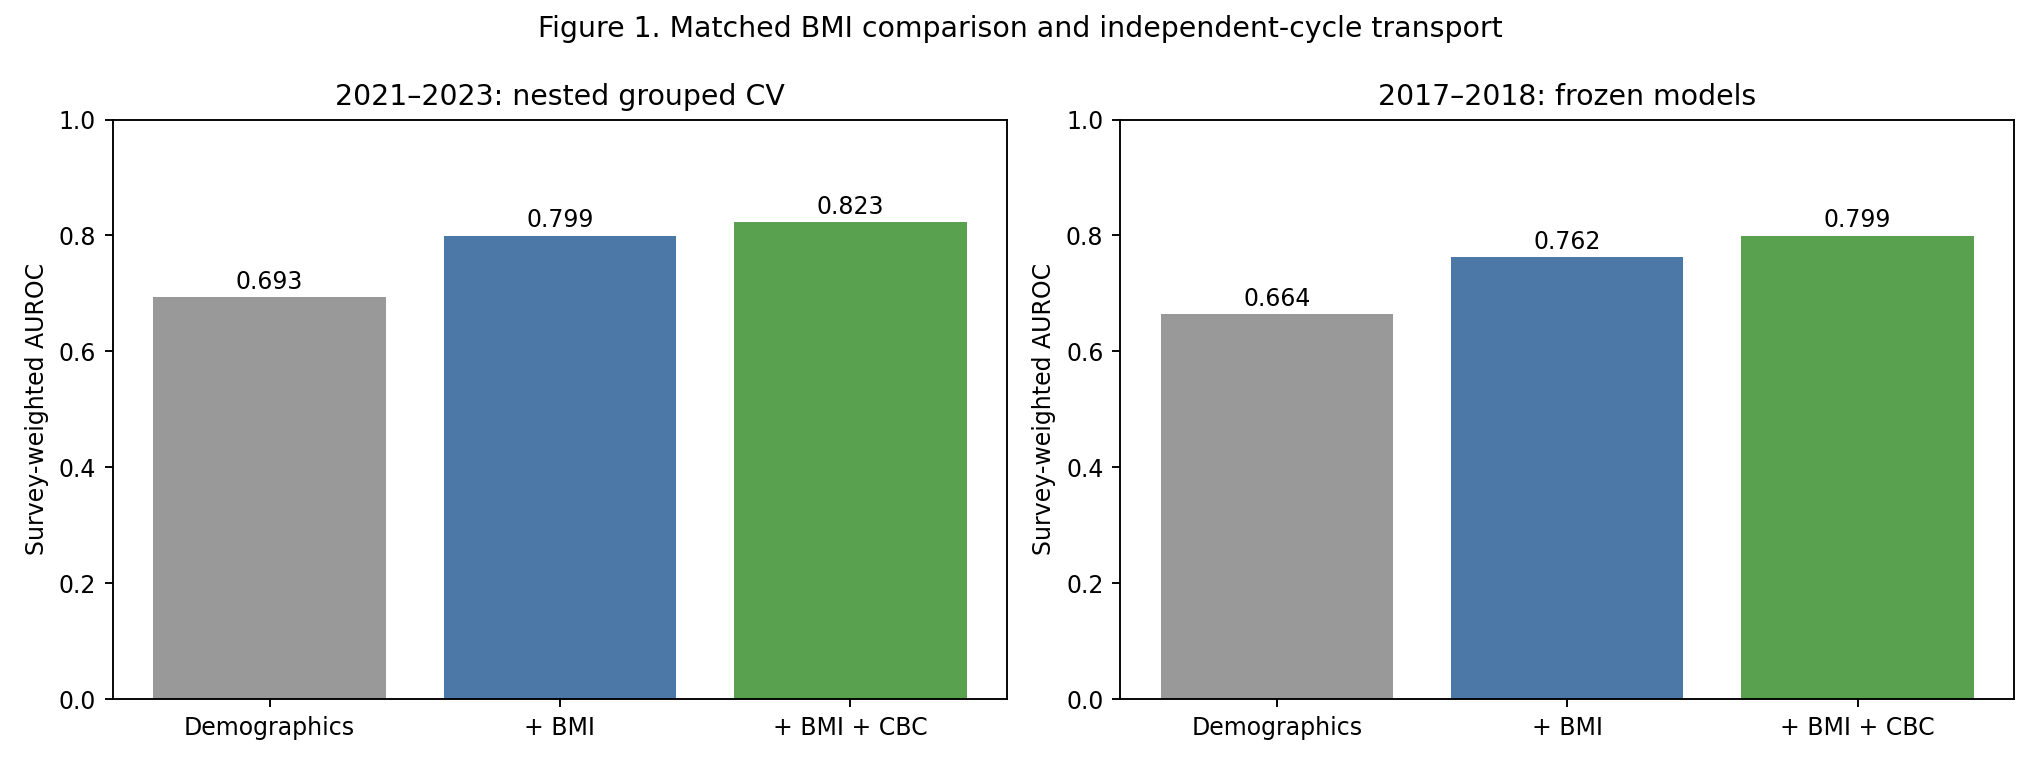

In [3]:
from IPython.display import Image, display
display(Image(filename=str(OUT / 'bmi_transport_comparison.png')))

Generated figure: `sensitivity_gains.png`. Interpret alongside the report; subgroup changes and assumed utility trade-offs do not establish causation or safety.

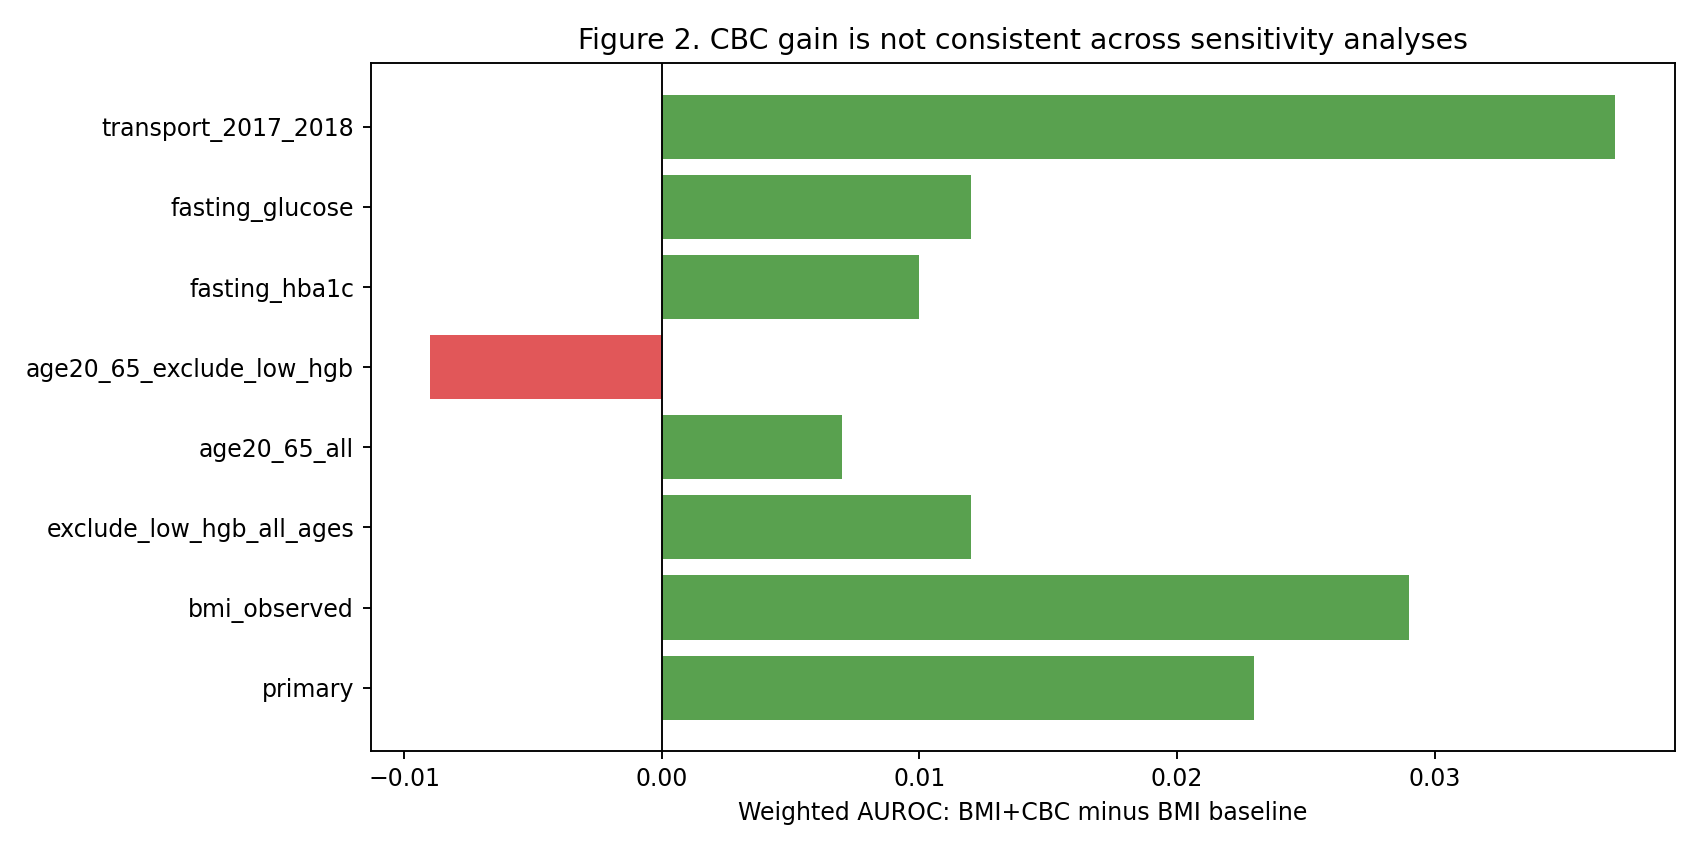

In [4]:
from IPython.display import Image, display
display(Image(filename=str(OUT / 'sensitivity_gains.png')))